# w12a — Comparing Many Means with One-Way ANOVA in Python
**ENGR 1451/2451 · Exploratory Data Science · Fall 2026**

This notebook accompanies **w12a: Comparing Many Means with ANOVA**.

We will analyze the **30 aldrin measurements at three Wolf River depths** using the supplied **`aldrin.csv`** file:

1. Read individual observations, summarize the three groups, and visualize their distributions.
2. Calculate **SST, SSG, SSE**, mean squares, **F**, its right-tail **P-value**, and $R^2$.
3. Confirm the calculations with **SciPy** and **statsmodels**, then consider the assumptions.
4. Compare pairs of means using **Bonferroni**-adjusted P-values.
5. Try an independent engineering example with a second, synthetic CSV.

In [3]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.precision", 4)
alpha = 0.05

## 1. Read `aldrin.csv` and compare the three depths

Each row is one measurement, with columns:

- `aldrin`: aldrin concentration in **nanograms per liter (ng/L)**, a quantitative response.
- `depth`: the sampling-depth category (`bottom`, `middepth`, or `surface`).

The file is stored at **`data/aldrin.csv`**. Keep the `data/` folder next to this notebook when running it.

In [4]:
csv_path = Path("data/aldrin.csv")
aldrin_data = pd.read_csv(csv_path)
print("Observations:", len(aldrin_data))
display(aldrin_data.head())

group_summary = (
    aldrin_data.groupby("depth")["aldrin"]
    .agg(n="size", mean="mean", sd="std")
)
display(group_summary.rename(index=str.title))
print(f"Grand mean: {aldrin_data['aldrin'].mean():.4f} ng/L")

Observations: 30


,aldrin,depth
0,3.8,bottom
1,4.8,bottom
2,4.9,bottom
3,5.3,bottom
4,5.4,bottom


,n,mean,sd
depth,,,
Bottom,10,6.04,1.5792
Middepth,10,5.05,1.1038
Surface,10,4.20,0.6600


Grand mean: 5.0967 ng/L


### Plot the individual observations and group means

The points are **actual entries from your supplied CSV** (only their horizontal positions are randomly jittered to avoid overlap). Orange horizontal marks indicate the sample means, and the dashed line indicates the grand mean. A separate boxplot appears later when we check the group spreads. Compare the separation of the group means with the spread within each depth.

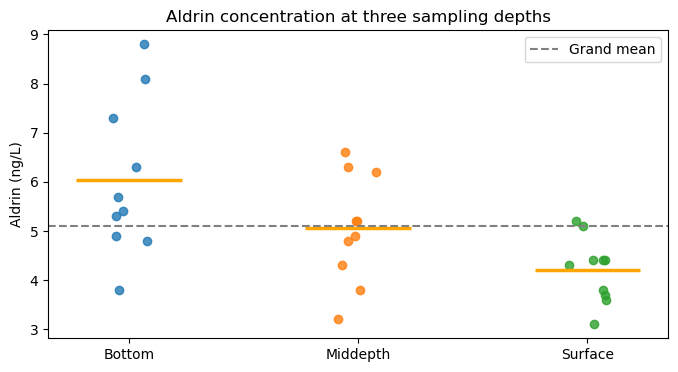

In [7]:
rng = np.random.default_rng(12)  # Jitter only x-coordinates

fig, ax = plt.subplots(figsize=(8, 4))
jitter_amount = 0.09
line_extent_half = .23
depth_order = aldrin_data["depth"].unique()

for i, depth in enumerate(depth_order, start=1):
    values = aldrin_data.loc[
        aldrin_data["depth"] == depth, "aldrin"
    ].to_numpy()
    x = i + rng.uniform(-jitter_amount, jitter_amount, size=len(values))
    ax.scatter(x, values, alpha=0.8)
    ax.hlines(values.mean(), i - line_extent_half, i + line_extend_half,
              color="orange", linewidth=2.5)

# Overall mean
ax.axhline(aldrin_data["aldrin"].mean(),
           color="gray", linestyle="--",
           label="Grand mean")

ax.set_xticks(range(1, len(depth_order) + 1))
ax.set_xticklabels([depth.capitalize() for depth in depth_order])
ax.set_ylabel("Aldrin (ng/L)")
ax.set_title("Aldrin concentration at three sampling depths")
ax.legend()

plt.show()



## 2. State hypotheses and decompose the variation

We are comparing three **population mean concentrations**:

$$H_0:\mu_B=\mu_M=\mu_S$$
$$H_A:\text{At least one population mean differs.}$$

**Check:** Does $H_A$ mean *every* pair differs? **No** — a single unequal pair makes $H_0$ false.

Let $y_{ij}$ denote observation $i$ in depth group $j$, with sample mean $\bar y_j$, group size $n_j$, and grand mean $\bar y$. For one-way ANOVA:

$$\underbrace{\sum_{j=1}^k\sum_{i=1}^{n_j}(y_{ij}-\bar y)^2}_{SST\text{: total}}
= \underbrace{\sum_{j=1}^k n_j(\bar y_j-\bar y)^2}_{SSG\text{: between groups}}
+ \underbrace{\sum_{j=1}^k\sum_{i=1}^{n_j}(y_{ij}-\bar y_j)^2}_{SSE\text{: within groups}}.$$

The fitted value for every observation in group $j$ is its **group mean** $\hat y_{ij}=\bar y_j$. This is the categorical-predictor counterpart of fitted values in regression.

In [ ]:
y = aldrin_data["aldrin"]
grand_mean = y.mean()
# Fitted value = mean of that observation's depth group.
fitted_group_mean = aldrin_data.groupby("depth")["aldrin"].transform("mean")

SST = ((y - grand_mean)**2).sum()                  # total
SSG = ((fitted_group_mean - grand_mean)**2).sum() # between groups
SSE = ((y - fitted_group_mean)**2).sum()          # within groups

print(f"Overall mean = {grand_mean:.4f} ng/L")
print(f"SST = {SST:.4f}; SSG = {SSG:.4f}; SSE = {SSE:.4f} (ng/L)²")
print(f"R² = SSG / SST = {SSG/SST:.4f}")

**Interpretation:** $R^2\approx0.312$ means the three-group model accounts for approximately **31% of the observed squared variation** among these 30 measurements. It is an **in-sample description**, not a claim that changing depth causes a concentration change.

## 3. Calculate the ANOVA F-statistic and P-value

For $k=3$ depths and $n=30$ observations:

$$df_{\rm groups}=k-1=2,\qquad df_{\rm error}=n-k=27,$$

$$MSG=\frac{SSG}{k-1},\qquad MSE=\frac{SSE}{n-k},\qquad
F=\frac{MSG}{MSE}.$$

**Important notation:** In this lecture, $MSE$ is the **ANOVA residual mean square** ($SSE/(n-k)$). It estimates the within-depth error **variance**, in units $(\mathrm{ng/L})^2$. In w06b, descriptive $RMSE=\sqrt{SSE/n}$ reported in-sample residual size in the original units. They are **not the same statistic**.

Under $H_0$ and the usual ANOVA assumptions, use an $F$ distribution with **two** degrees of freedom parameters: $F_{2,27}$. A large observed $F$ gives a small **right-tail** P-value.

In [ ]:
k = aldrin_data["depth"].nunique()
n = len(aldrin_data)
df_groups = k - 1
df_error = n - k

MSG = SSG / df_groups
MSE = SSE / df_error
F = MSG / MSE
p_value = stats.f.sf(F, df_groups, df_error)  # survival = right-tail area

anova_manual = pd.DataFrame({
    "source": ["Between groups", "Within groups", "Total"],
    "df": [df_groups, df_error, n - 1],
    "sum_sq": [SSG, SSE, SST],
    "mean_sq": [MSG, MSE, np.nan],
    "F": [F, np.nan, np.nan],
    "p_value": [p_value, np.nan, np.nan],
})
display(anova_manual)
print(f"F({df_groups}, {df_error}) = {F:.4f}, P = {p_value:.6f}")
print(f"Residual standard deviation estimate, sqrt(MSE) = {np.sqrt(MSE):.3f} ng/L")
print(f"Descriptive in-sample RMSE, sqrt(SSE/n) = {np.sqrt(SSE/n):.3f} ng/L")
print("Decision at alpha=0.05:", "Reject H0" if p_value < alpha else "Fail to reject H0")

**Interpretation check:** The CSV gives approximately $F(2,27)=6.134$ and $P=0.00637$. Since $P<0.05$, the data provide evidence that **at least one population mean aldrin concentration differs**, *if the sampling design and model assumptions justify inference*. The overall F-test **does not identify which pairs differ**.

Use the calculated CSV values for numerical results; small differences can arise when intermediate values are rounded for display.

In [ ]:
x_f = np.linspace(0.001, 15, 600)
f_density = stats.f.pdf(x_f, df_groups, df_error)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(x_f, f_density, label=f"F distribution ({df_groups}, {df_error})")
ax.fill_between(x_f, 0, f_density, where=x_f >= F, alpha=0.3,
                label=f"Right-tail P = {p_value:.5f}")
ax.axvline(F, linestyle="--", label=f"Observed F = {F:.2f}")
ax.set_xlim(0, 15)
ax.set_xlabel("F statistic")
ax.set_ylabel("Probability density")
ax.legend()
plt.show()

## 4. Check the results with SciPy and `statsmodels`

`stats.f_oneway()` tests equality of group means using separate arrays. An equivalent one-way ANOVA can be fitted by least squares using `statsmodels`:

- `aldrin ~ C(depth)` treats **depth as categorical**, not numeric.
- `sm.stats.anova_lm(fit, typ=2)` displays the ANOVA table.
- The fitted value for each observation is its sample **depth mean**.

The `statsmodels` regression coefficient summary is a *different representation* of the same group-mean model; the ANOVA table is the clearest output for the **overall F-test**.

In [ ]:
groups = [
    aldrin_data.loc[aldrin_data["depth"] == depth, "aldrin"].to_numpy()
    for depth in depth_order
]
sci_result = stats.f_oneway(*groups)
print(f"SciPy: F = {sci_result.statistic:.4f}, P = {sci_result.pvalue:.6f}")

fit = smf.ols("aldrin ~ C(depth)", data=aldrin_data).fit()
print("statsmodels ANOVA table:")
display(sm.stats.anova_lm(fit, typ=2))
print(f"statsmodels R² = {fit.rsquared:.4f}")
print(f"statsmodels residual MSE = {fit.mse_resid:.4f} (ng/L)²")

## 5. Check assumptions before trusting the P-value

Classical independent-groups one-way ANOVA assumes:

1. **Independence within and between depths.** Sampling at the *same sites* at multiple depths creates pairing, so the usual independent-groups test may be inappropriate. **The CSV does not identify sampling sites or collection times**, so this cannot be established from the data alone.
2. **Approximately normal errors within each depth** (particularly important at $n=10$ per group). Look at each depth's observations or a Q-Q plot, not just the pooled data.
3. **Similar population variances across groups.** Compare group SDs and boxplots. A larger-to-smaller sample SD ratio much above 2 is a reason to investigate, not an automatic pass/fail rule.

ANOVA software cannot verify the sampling design. A significant P-value does not establish causation or correct a biased sampling method.

In [ ]:
print("Sample standard deviations (ng/L):")
print(group_summary["sd"])
print(f"Largest / smallest SD = "
      f"{group_summary['sd'].max()/group_summary['sd'].min():.2f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot(groups, tick_labels=[depth.capitalize() for depth in depth_order])
ax.set_title("Aldrin spread by depth (supplied aldrin.csv)")
ax.set_xlabel("Sampling depth")
ax.set_ylabel("Aldrin (ng/L)")
plt.show()

# Discuss: Do the spreads look similar? Could depths from a single site be paired?

## 6. After ANOVA, which pairs differ?

A significant global F-test says **at least one mean differs**, but does not identify a pair. For $k=3$ groups, there are

$$K=\frac{k(k-1)}{2}=3\quad\text{pairwise comparisons}.$$

With a **Bonferroni correction**, compare each two-sided P-value to $\alpha/K=0.05/3\approx0.0167$. Equivalently, multiply each P-value by $K$ (capped at 1) and compare the adjusted result with $0.05$.

Under the *equal-variance ANOVA model*, use the pooled within-group mean square $MSE$:

$$t=\frac{\bar y_a-\bar y_b}{\sqrt{MSE(1/n_a+1/n_b)}},\qquad df=n-k.$$

**Remember:** Bonferroni is a correction for testing multiple comparisons. It is **not** the ANOVA F-test.

In [ ]:
pair_rows = []
for depth_a, depth_b in combinations(depth_order, 2):
    a = aldrin_data.loc[aldrin_data["depth"] == depth_a, "aldrin"]
    b = aldrin_data.loc[aldrin_data["depth"] == depth_b, "aldrin"]
    difference = a.mean() - b.mean()
    se = np.sqrt(MSE * (1/len(a) + 1/len(b)))
    t_stat = difference / se
    p_raw = 2 * stats.t.sf(abs(t_stat), df_error)
    pair_rows.append({"comparison": f"{depth_a.title()} vs {depth_b.title()}",
                      "mean_difference_ng_l": difference,
                      "t": t_stat, "p_raw": p_raw})

pairs = pd.DataFrame(pair_rows)
K = len(pairs)
pairs["p_bonferroni"] = np.minimum(K * pairs["p_raw"], 1)
pairs["significant_5pct"] = pairs["p_bonferroni"] < alpha

display(pairs.round(4))
print(f"Bonferroni threshold per comparison: alpha/K = {alpha/K:.4f}")

**Interpretation check:** For this CSV, only **Bottom vs Surface** is significant after the three Bonferroni-adjusted comparisons (adjusted $P\approx0.0049$). Bottom vs Middepth and Middepth vs Surface are **not** significant under this procedure. Not finding a significant difference is **not proof of equality**.

The pairwise tests above use the pooled within-group variance from the classical ANOVA. The sample SDs (about 1.58, 1.10, and 0.66) differ noticeably, so discuss whether the equal-variance assumption is adequate before generalizing the conclusions.

### Python function reference

| Function or attribute | Purpose |
|---|---|
| `stats.f.sf(F, df1, df2)` | Compute the right-tail ANOVA P-value. |
| `stats.f_oneway(*groups)` | Run standard one-way ANOVA from group arrays. |
| `smf.ols("aldrin ~ C(depth)", data=df).fit()` | Fit group means with a categorical predictor. |
| `sm.stats.anova_lm(fit, typ=2)` | Display the ANOVA table. |
| `fit.rsquared`, `fit.mse_resid` | Read model $R^2$ and error mean square. |
| `stats.t.sf(abs(t), df)` | Right tail of a $t$ distribution (multiply by two for a two-sided test). |

**Key distinction:** $MSE=SSE/(n-k)$ is a **variance estimate** with squared units. Descriptive $RMSE=\sqrt{SSE/n}$ is measured in the response units. Neither the significance test nor $R^2$ establishes a causal effect.

## Your turn — coating methods (in-class exercise)

The file `data/coating_strength_methods.csv` contains tensile strengths (MPa) for **36 coupons** prepared by **Dip, Spray, or Spin** coating.

1. Find the **mean strength** for each method.
2. State $H_0$ and $H_A$ and run a **one-way ANOVA** using `smf.ols` in `statsmodels`.
3. At $\alpha=0.05$, what do you conclude?

In [ ]:
coating = pd.read_csv("data/coating_strength_methods.csv")
# 1. Mean strength by method:

# 2. H0, HA, and one-way ANOVA:

# 3. Conclusion at alpha = 0.05:
